In [44]:
# from Zhiheng's message
# I would say that the position of the collimator changed a little bit
# but we also redid the measurement, so the 28.5 would be more accurate.
# We also rotated the collimator on 0303, so I'd say everything before that
# is closer to 28cm, and everything after is closer to 28.5

## fucking still:
# do I use rate or total counts for comparison

# do i change binRange with scaling number (no?)

# so do i try profile likelihood?

#### What does this code do (eventually) ####

## notes to fix the chi2 global value

# need to sort out the Nbins/dof stuff. sum chi2 before reducing to handle the single free parameter over many bins
# but maybe have to do some probability stuff. 

# some errors don't come through. like the number of counts in background data. The only errors in chi2 some from
# the MC counts (and should include the data counts). Also what about bin-to-bin fluctutions, counts are correlated
# like if something isn't in 3PE bin it will be in 2 or 4PE bin
# I guess this is why our chi2 is lower than 1?

# also the binrange, need to look at both datasets to make sure in poisson--> gaussian regime.
# maybe sum the uncertainties in the denominator of chi2 calculation? but that doesn't make total sense

# what would the complete likelihood look like? not too bad, just sampling from poisson a bunch of times.


# need to sit down and redo the mapping
# 1. have mapping not depend on what realdata and mc is there
# 2. have toggles to select which datasets gets included.
# 3. have easy way to modify info that maps data (or mapping of data)
# 4. equivalent to above, modify what gets considered as part of chi2 calculation

In [45]:
# need to implement LP filter. also in G4_runClasses and mac. right now set to false
# see xxLP in code

In [46]:
## Python Stuff
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import json5

os.environ.get("ROOTSYS")

"""
run with:
see code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab see bashprofile
"""

## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(300)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
ROOT.enableJSVis()
# ROOT.disableJSVis()

In [47]:
## prepping to get tools for real data
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME"))

# so we can use makeDataObj.py
THISPATH = os.environ.get("CF4HOME")+"/comp1/"
sys.path.append(THISPATH)

## Loading Atown's tools
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

print(sys.path)

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code

In [48]:
##### user controls #####
THISPATH = os.environ.get("CF4HOME")+"/comp1/"
with open(THISPATH+'config.json', 'r') as file:
  config = json5.load(file)

NBINS = config.get("global_analysis").get("nBins")
BINLOW = config.get("global_analysis").get("binLow")
BINHIGH = config.get("global_analysis").get("binHigh")
print(NBINS, BINLOW, BINHIGH)

FIRSTBIN = config.get("global_analysis").get("range_lowBin")
# print("firstBin:", FIRSTBIN)

GLOBALVERBOSE = config.get("global_analysis").get("verbose")

USEAVG = config.get("data_analysis").get("avg_background")
USEAVG = True
# USEAVG = False

hScale = config.get("cesiumBareData").get("hScale")

NCA = config.get("mc_analysis").get("NCA")


# config.get("data_analysis").get("defData_Path")
# config.get("cesiumBareData").get("bkgList")


50 0.5 100.5


In [49]:
## -------- Loading in real CS data -------- ##
if "RAN_CS" in globals() and "rcl_cs_bare_heights" in globals():
  print(f"RAN_CS is true, not reloading data")
else:
    print(f"RAN_CS is not declared. running code")
    makeDataArg = str(THISPATH + "makeDataObj_cs.py")
    %run $makeDataArg

if "RAN_CO" in globals() and "rcl_co_bare_heights" in globals():
  print(f"RAN_CO is true, not reloading data")
else:
  print(f"RAN_CO is not declared. running code")
  makeDataArg = str(THISPATH + "makeDataObj_co.py")
  %run $makeDataArg

def forloop_bkg_subtraction(rcList, histName, useAvg = True):
  for rc in rcList:
    if useAvg:
      rc.BuildCorrSpectrum(histName)
    else:
      rc.BuildCorrSpectrum()
    rc.setup_forComparison()
    print(rc.mHeight)

# xx is running this multiple times okay? yes.
# ------------- Get and build the bkg corrected spectra ------------- ##
print("\n Cs, Bare:")
forloop_bkg_subtraction(rcl_cs_bare_heights, hNPE_bkg_0310, USEAVG)

print("\n Cs, Filtered")
forloop_bkg_subtraction(rcl_cs_lp_heights, hNPE_bkg_0411, USEAVG)

print("\n Co, Bare:")
forloop_bkg_subtraction(rcl_co_bare_heights, hNPE_bkg_0303, USEAVG)

print("\n Co, Filtered")
forloop_bkg_subtraction(rcl_co_lp_heights, hNPE_bkg_0413, USEAVG)


RAN_CS is true, not reloading data
RAN_CO is true, not reloading data

 Cs, Bare:
26.5
28
30.5
32
34.5

 Cs, Filtered
26
28.5
30.5
32.0

 Co, Bare:
28.0
30.5
33.0

 Co, Filtered
26
28.5
30.5


In [50]:
# this is all the files in a single folder
class RealDataSet(object):

  def __init__(self):
    
    ## only Cs data right now
    self.mCsBare = []
    self.mCsLP = []

    self.mCoBare = []
    self.mCoLP = []

    return

  def print(self, hSub = 0, verbose = True):
    
    print("\n---- RealDataSet print() ----")
    if verbose:
      print("mCsBare[0] print():", end = "")
      self.mCsBare[0].print()

      print("\nmCoBare[0] print()", end = "")
      self.mCoBare[0].print()
    
    wid = 6
    print("    h         Nraw        Nsub     rate (Hz)    subRate (Hz)")
    print("csBare:")
    [print(f"| {hSub - rc.mHeight: > {wid}.{1}f} |  {rc.tt.GetEntries():>{wid}.{1}e}  |  {rc.GetCorrSpectrum().GetEntries():>{wid}.{2}e}  |  {rc.GetRate():>{wid}.{2}f} | {rc.mCorrBkgRate:>{wid}.{2}f}") for rc in self.mCsBare]

    print("\ncoBare:")
    [print(f"| {hSub - rc.mHeight: > {wid}.{1}f} |  {rc.tt.GetEntries():>{wid}.{1}e}  |  {rc.GetCorrSpectrum().GetEntries():>{wid}.{2}e}  |  {rc.GetRate():>{wid}.{2}f} | {rc.mCorrBkgRate:>{wid}.{2}f}") for rc in self.mCoBare]

    return
  
  def buildOutArrays(self):

    self.gammaMap = {"csb": self.mCsBare, "cslp": self.mCsLP, "cob": self.mCoBare, "colp": self.mCoLP}
    return
  
  def findRunByHeight(self, height, key = "csb"):
    # [print(rc.mHeight) for rc in self.gammaMap.get(key)]
    found = next((rc for rc in self.gammaMap.get(key) if rc.mHeight == height), None)
    if found == None:
      print(f"ERROR: no mc object found in rc {key} with height {height}")
    return found
  
  
  # def plot_singleRows(self, fig: plt.figure, selection = "mCsBare",):
  #   Nrows = len(getattr(self, selection))

  #   for i, rc in enumerate(getattr(self, selection)):
  #     ax = fig.add_subplot.hist(Nrows, 1, i+1)
  #     ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype = "step", label = "data " + str(hScale - rcBare_55cm.mHeight) + " cm")
  #   return


In [51]:
realData = RealDataSet()

# get rid of the data below SiPM
cs_bare_heights = [x for x in cs_bare_heights if x != 34.5]
print("Cs bare heights to look for:", cs_bare_heights)
bareCsData_rc = [SORTING.findRCbyHeight(h, rcl_cs_bare_heights) for h in cs_bare_heights] # prune off 34.5 one

# sorting from lowest to highest (nice)
bareCsData_rc = sorted(bareCsData_rc, key=lambda rc: hScale - rc.mHeight) # sorting
# print(type(bareCsData_rc[0]))

print("Cs data heights:")
print(" Bare", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in bareCsData_rc]; print("")

# sorting Cs LP data
lpCsData_rc = sorted(rcl_cs_lp_heights, key=lambda rc: hScale - rc.mHeight) # sorting
print(" LP", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in lpCsData_rc]; print("\n")
# bareCsData_rc[0].print()

# sorting Co data
print("Co bare heights to look for:", co_bare_heights)
bareCoData_rc = sorted(rcl_co_bare_heights, key = lambda rc: hScale - rc.mHeight)
lpCoData_rc = sorted(rcl_co_lp_heights, key = lambda rc: hScale - rc.mHeight)
# print(type(bareCoData_rc[0]))
print("Co data heights")
print(" Bare", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in bareCoData_rc]; print("")
print(" LP", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in lpCoData_rc]; print("")

## assigning rc lists to realData object
realData.mCsBare = bareCsData_rc
realData.mCsLP = lpCsData_rc
realData.mCoBare = bareCoData_rc
realData.mCoLP = lpCoData_rc
realData.buildOutArrays()

realData.findRunByHeight(height = hScale - 0.0)

# for rc in realData.mCsBare:
#   print(rc.GetRunTime())

Cs bare heights to look for: [26.5, 28, 30.5, 32]
Cs data heights:
 Bare: 0.0 1.5 4.0 5.5 
 LP: 0.0 1.5 3.5 6.0 

Co bare heights to look for: [28.0, 30.5, 33.0]
Co data heights
 Bare: -1.0 1.5 4.0 
 LP: 1.5 3.5 6.0 


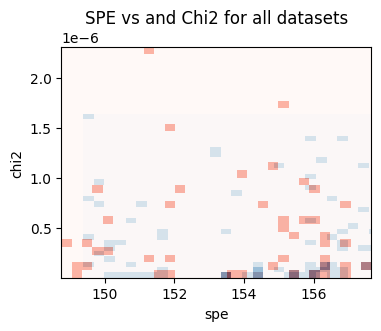

In [52]:
## checking spe and chi2 values
fig, ax = plt.subplots(1, 1, figsize=(4, 3))
ax.hist2d(speList, chi2List, bins=30, cmap='Blues', cmin = 0.0, alpha = 1.)

# # modify existing Reds colormap with a linearly fading alpha
# red = pl.cm.Reds  # original colormap
# fading_red = red(np.arange(red.N)) # extract colors
# fading_red[:, -1] = np.linspace(0, 1, red.N) # modify alpha
# fading_red = ListedColormap(fading_red) # convert to colormap

ax.hist2d(speListCo, chi2ListCo, bins=30, cmap="Reds", alpha = 0.5)
ax.set_title("SPE vs and Chi2 for all datasets")
ax.set_xlabel("spe")
ax.set_ylabel("chi2")

plt.show()

In [53]:
# this will take in a folder and create the MC dataset
# # and an set 

# Geant4 code and helpers
sys.path.append(os.environ.get("CF4G4"))
import Batch.helpers.FileGetters as FG

from Batch.helpers.G4_runClasses import *
from Batch.helpers.G4_macHelpers import *

# this is all the files in a single folder
class MCdataSet(object):

  def __init__(self, folderPath: str, verbose = 1):
    
    files = FG.get_all_root_files(folderPath)
    self.fpath = folderPath
    if verbose == 1:
      print(files)
    # open everything as FullMCRun
    # sort by mRunPars

    # entire trackers
    self.mAllRuns = [FullMCRun(macName = f[:-len(".root")], verbose = verbose) for f in files]
    self.buildOutDataArrays()

    # gamma Map
    # self.gammaMap = {"csb": self.mCsBareList, "cslp": self.mCsLpList, "cob": self.mCoBareList, "colp": self.mCoLPList}
    return
  
  def popHeights(self, csBare = [], csLP = [], coBare = [], coLP = []):
    self.mCsBareList = [mc for mc in self.mCsBareList if mc.mRunPars.gammaHeight not in csBare]
    self.mCoBareList = [mc for mc in self.mCoBareList if mc.mRunPars.gammaHeight not in coBare]
    return
  
  # call this after changing something from mAllRuns. this resets matrices with everything from mAllRuns
  # need to 'delete' the item from mAllRuns or something
  def buildOutDataArrays(self):
    ## loading (Bare) Cs data
    self.mCsBareList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == False and mc.mRunPars.gammaSrc == "Cs137")]
    self.mCsBareList = sorted(self.mCsBareList, key=lambda rc: rc.mRunPars.gammaHeight) # sorting
    # [print(type(mc.mRunPars.gammaHeight)) for mc in self.mCsBareList]
    self.mCsBareRateScaling = 0.1 # float
    
    self.mCsLpList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == True and mc.mRunPars.gammaSrc == "Cs137")]
    self.mCsLpList = sorted(self.mCsLpList, key=lambda rc: rc.mRunPars.gammaHeight) # sorting

    ## Co data
    self.mCoBareList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == False and mc.mRunPars.gammaSrc == "Co57")]
    self.mCoBareList = sorted(self.mCoBareList, key = lambda rc: rc.mRunPars.gammaHeight)
    self.mCoLPList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == True and mc.mRunPars.gammaSrc == "Co57")]
    self.mCoLPList = sorted(self.mCoLPList, key = lambda rc: rc.mRunPars.gammaHeight)
    self.mCoBareRateScaling = 0.1 #float

    # gamma Map
    self.gammaMap = {"csb": self.mCsBareList, "cslp": self.mCsLpList, "cob": self.mCoBareList, "colp": self.mCoLPList}

    ## other data\
    return
  
  def findRunByHeight(self, height, key = "csb"):
    found = next((mc for mc in self.gammaMap.get(key) if mc.mRunPars.gammaHeight == height), None)
    if found == None:
      print(f"no mc object found in mc {key} with height {height}")
    return found

  def doCAcorrection_BinomialMC(self, nCA):
    done = [mc.doCAcorrection_BinomialMC(NCA) for mc in self.mAllRuns]
    return
  
  # for "mNPE", "mNPE_corr", call one of the doCAcorrection first
  def setup_forComparison(self, Nbins = 100, lowRange = 0.5, maxRange = 100.5, variable = "mNPE"):
    done = [mc.setup_forComparison(NBINS, lowRange, maxRange, variable) for mc in self.mAllRuns]
    return
  
  # def compare_dicts(dict1, dict2):
  #   return all(dict1.get(key) == dict2.get(key) for key in dict1.keys())

  def print(self):
    print("---- mcDataSet.print() ----")
    print(self.fpath, "\n")
    print("self.mCsBareList[0]", self.mCsBareList[0].mPhysPars)
    print("self.mCsBareList[0]", self.mCsBareList[0].mRunPars)
    # print("Cs Bare heights")
    [print(mc.mRunPars.gammaHeight, end = " ") for mc in self.mCsBareList];

    print("\nself.mCoBareList[0]", self.mCoBareList[0].mRunPars)
    [print(mc.mRunPars.gammaHeight, end = " ") for mc in self.mCoBareList]
    print()
    return
  
  # check that all physPars are the same (they should be)
  # detPars aren't implemented yet (only PDE)
  def check_physPars_andDetPars(self, verbose = 1):

    physParList = [mc.mPhysPars for mc in self.mAllRuns]
    if verbose == 2:
      [print(mc.mPhysPars.__dict__, "\n") for mc in self.mAllRuns]
    a = all(physParList[0] == p1 for p1 in physParList[1:])
    if a == True:
      if verbose:
        print("\nphys Pars consistent for", self.fpath)
        print(self.mCsBareList[0].mPhysPars)
      return a
    else:
      print("ERROR, physPars inconsistent for", self.fpath)
    return a

In [54]:
# should have this working as a two way object (rc and mc also know about it)
class rcMCpair(object):

  def __init__(self, rc, mc):
    self.mc = mc
    self.rc = rc
    self.height = mc.mRunPars.gammaHeight
    self.countLimit = 10
    self.ndof = -1
    return
  
  def SetBinRanges(self, firstBin = 1):

    self.firstBin = firstBin

    find_index = lambda arr, X: next((i for i, value in enumerate(arr) if value < X), len(arr) - 1)
    dataLastBin = find_index(self.rc.mBin_rawCounts, self.countLimit)
    mcLastBin = find_index(self.mc.mRaw_Counts, self.countLimit)
    self.lastBin = min(dataLastBin, mcLastBin)

    # safety. shouldn't enter this?
    while self.mc.mRaw_Counts[self.lastBin] < self.countLimit or self.rc.mBin_rawCounts[self.lastBin] < self.countLimit:
      self.lastBin -= 1

    # print(self.mc.mRunPars)
    # print(self.firstBin, self.lastBin)
    # print(self.rc.mBin_rawCounts[0: self.lastBin + 3])
    self.ndof = self.lastBin - self.firstBin
    return

  ##----------##
  def GuessScaling(self):
    # analytic scaling
    dataArea = sum(self.rc.mBin_rawCounts[self.firstBin:self.lastBin]) / self.rc.GetRunTime() #xx
    self.mcScale = dataArea / np.sum(self.mc.mRaw_Counts[self.firstBin:self.lastBin])
    return self.mcScale # this is now proportional to the runtime. has units 1/time

  def GetMaxBin(self, scaling, rawCounts = True):
    if rawCounts:
      a = max(np.maximum(self.rc.mBin_rawCounts, scaling * self.mc.mRaw_Counts * self.rc.GetRunTime()))
      return a
    else:
      a = max(np.maximum(self.rc.mBin_rawCounts / self.rc.GetRunTime(), scaling * self.mc.mRaw_Counts ))
      return a

  ##----------##
  def computeChi2_reduced(self, scaling):
    if not hasattr(self, "lastBin") or not hasattr(self, "firstBin"):
      print("WARNING in rcmcPair.computeChi2_reduced: first and lastBin not set. Call SetBinRanges() first")
      return -1
      # self.SetBinRanges(firstBin)
      # return -1
  
    mcBins = scaling * (self.mc.mRaw_Counts[self.firstBin:self.lastBin]) * self.rc.GetRunTime()
    dataBins = self.rc.mBin_rawCounts[self.firstBin:self.lastBin]  #/ self.rc.GetRunTime()
    self.chi2 = np.sum((dataBins - mcBins)**2/mcBins)
    self.nbinsUsed = self.lastBin - self.firstBin
    self.redChi2 = self.chi2/self.ndof
    # xx I was initally subtracting -1 from denominator above. but that reduces for the scaling too many times
    # total statistic = (X1 + X2 + X3 + ...)/(ndof1 + nbins2 + nbins3 + ... - nParameters(1 here))
    # I don't like this because it is not summing the reduced chi2, but summing all then reducing which we thought gave a different absolute value
    # I was doing extra -1 subtraction for every run
    # return self.redChi2
    return self.chi2, self.ndof

# do i make another object to track chi2 scores, nuisance pars, etc?

import scipy.optimize as spOpt
from helpers.anaStructs import * # includes SORTING class/namespace
import json5
########################################
class Comparator(object):

  def __init__(self, realData):

    self.mMCDataSet = None
    self.mRealData = realData # this never changes

    self.hScale = hScale

    ## Cesium
    self.csBareMap = [None] * len(self.mRealData.mCsBare)
    self.csGuess = -1
    self.csBareNuis = -1
    self.csBareChi2 = -1
    self.csBareNDOF = 0

    ## Co
    self.coBareMap = [None] * len(self.mRealData.mCoBare)
    self.coGuess = -1
    self.coBareNuis = -1
    self.coBareChi2 = -1
    self.coBareNDOF = 0

    self.totalRedChi2 = -1
    return
  
  def loadNewG4(self, mc, verbose = 1):
    # load it
    self.mMCDataSet = mc

    # give it a physPars copy
    return True

  # how to track heights and map them to one another. 
  def do_mapping(self):

    # check lengths
    if (len(self.mMCDataSet.mCsBareList) != len(self.mRealData.mCsBare)):
      print("mc csBare list not equal to realData list")
      return False

    # BareCs mapping
    for i, mc in enumerate(self.mMCDataSet.mCsBareList): # here mc is a FullMCRun object
      h = mc.mRunPars.gammaHeight # get height
      rc_withHeight = SORTING.findRCbyHeight(self.hScale - h, self.mRealData.mCsBare) # get real data
      pair = rcMCpair(rc_withHeight, mc) # make pair object to map them together
      # print(hScale - rc_withHeight.mHeight, pair.mc.mRunPars.gammaHeight == self.hScale - rc_withHeight.mHeight) 
      self.csBareMap[i] = pair # assign pair to the map list
    
    # doing BareCo mapping
    for i, mc in enumerate(self.mMCDataSet.mCoBareList): # here mc is a FullMCRun object
      h = mc.mRunPars.gammaHeight # get height
      # print(mc.mRunPars)
      # print(h)
      rc_withHeight = SORTING.findRCbyHeight(self.hScale - h, self.mRealData.mCoBare) # get real data
      # print(h, type(rc_withHeight))
      pair = rcMCpair(rc_withHeight, mc) # make pair object to map them together
      # print(hScale - rc_withHeight.mHeight, pair.mc.mRunPars.gammaHeight == self.hScale - rc_withHeight.mHeight) 
      self.coBareMap[i] = pair # assign pair to the map list
    
    # print(len(self.csBareMap))
    return True
  
  # should also have option to just pass a 'pure' height list
  def do_mapping_fromJson(self, config, subtract = 0.0, verbose = False):
    print("in do_mapping_fromJson") if verbose else None 

    # csBare mapping
    dic_csBare = config.get("global_analysis").get("csBareMap")
    self.csBareMap = [None] * len(dic_csBare)
    print("CsBare") if verbose else None
    for i, (mch, datah) in enumerate(dic_csBare.items()):
      mc = self.mMCDataSet.findRunByHeight(float(mch), key = "csb")
      rc = self.mRealData.findRunByHeight(datah, key = "csb")
      if mc != None and rc != None:
        pair = rcMCpair(rc, mc) # make pair object to map them together
        self.csBareMap[i] = pair # assign pair to the map list
        print(mc.mRunPars.gammaHeight, rc.mHeight) if verbose else None
    
    # coBare mapping
    dic_coBare = config.get("global_analysis").get("coBareMap")
    self.coBareMap = [None] * len(dic_coBare)
    print("\nCoBare") if verbose else None
    for i, (mch, datah) in enumerate(dic_coBare.items()):
      mc = self.mMCDataSet.findRunByHeight(float(mch), key = "cob")
      rc = self.mRealData.findRunByHeight(datah, key = "cob")
      if mc != None and rc != None:
        pair = rcMCpair(rc, mc) # make pair object to map them together
        self.coBareMap[i] = pair # assign pair to the map list
        print(mc.mRunPars.gammaHeight, rc.mHeight) if verbose else None
    
    if None in self.coBareMap or None in self.csBareMap:
      print("some None elements exist in COMPARATOR object maps")
      return False
    return True

  def print(self, mcVerb = True, dataVerb = True): # incomplete
    print("---- comparator.print() subcalls ----\n")

    self.mMCDataSet.print() if mcVerb else None

    self.mRealData.print(verbose = dataVerb, hSub = self.hScale)

    print("\n---- COMPARATOR.print() ----")
    print("heights in pairMaps:")
    print("csBare:", end = " ")
    [print("{", self.hScale - pair.rc.mHeight, " : ", pair.mc.mRunPars.gammaHeight, "}", sep = "", end = " ")for pair in self.csBareMap]

    print("\ncoBare:", end = " ")
    [print("{", self.hScale - pair.rc.mHeight, " : ", pair.mc.mRunPars.gammaHeight, "}", sep = "", end = " ")for pair in self.coBareMap]

    return
  
  def SetBinRanges(self, firstBin = 1):
    [rcmc.SetBinRanges(firstBin) for rcmc in self.csBareMap] # Cs
    [rcmc.SetBinRanges(firstBin) for rcmc in self.coBareMap] # Co
    return
  
  def checkNDOF(self):
    return all(p.ndof != 0 for p in self.csBareMap + self.coBareMap)
  
  def GuessOverallScaling(self): # call guess scaling for each pair to get overall scaling
    ## Cs (just bare or both?)
    self.csGuess = np.sum([pair.GuessScaling() for pair in self.csBareMap])/len(self.csBareMap)
    self.csBareNuis = self.csGuess

    ## Co (just bare or both?)
    self.coGuess = np.sum([pair.GuessScaling() for pair in self.coBareMap])/len(self.coBareMap)
    self.coBareNuis = self.coGuess
    return 0.

  ## this one does everything, but nuisance params don't use this exact output
  def getFullReducedChi2(self):
    if not hasattr(self, "coGuess") or not hasattr(self, "csGuess"):
      self.GuessOverallScaling()
    
    self.getCsBarechi2(scaling = self.csBareNuis)
    self.getCoBarechi2(scaling = self.coBareNuis)
    self.totalRedChi2 = (self.csBareChi2 + self.coBareChi2)/(self.csBareNDOF + self.coBareNDOF - 2)
    return self.totalRedChi2
  
  # use for Cs nuisance param
  def getCsBarechi2(self, scaling = None):
    if scaling == None:
      self.csBareNuis = self.csGuess
    else:
      self.csBareNuis = scaling
    
    csBarePairValues = np.array([pair.computeChi2_reduced(self.csBareNuis) for pair in self.csBareMap]) # do calculation
    self.csBareChi2 = np.sum(csBarePairValues[:, 0])
    self.csBareNDOF = np.sum(csBarePairValues[:, 1])
    self.csBareRedChi2 = self.csBareChi2/(self.csBareNDOF - 1)
    return self.csBareChi2
  
  # use for Co nuisance param
  def getCoBarechi2(self, scaling = None):
    if scaling == None:
      self.coBareNuis = self.coGuess
    else:
      self.coBareNuis = scaling
      
    coBarePairValues = np.array([pair.computeChi2_reduced(self.coBareNuis) for pair in self.coBareMap]) # do calculation
    self.coBareChi2 = np.sum(coBarePairValues[:, 0])
    self.coBareNDOF = np.sum(coBarePairValues[:, 1])
    self.coBareRedChi2 = self.coBareChi2/(self.coBareNDOF - 1)
    # print("full Co X2 = ", self.coBareChi2)
    return self.coBareChi2

  def minimizeRateScaling(self, option = "CsBare", manual = False, verbose = 0): # nuisance parameter for these dataSets
    # options are CsBare, CoBare, ...
    opts = ["CoBare", "CsBare"]

    # tryAgain: add a couple attempts with improved minimizer, also add option to do manually
    # (find min of some 1d space like above), also allow option to specify which function gets passed.
    minOptions = {'maxiter': 1000, 'disp': False, 'xatol': 1e-5, 'fatol':1e-5 }
    
    self.GuessOverallScaling() # sets up firstGuesses

    # Cesium Bare by default
    funToUse = self.getCsBarechi2
    guess = self.csGuess
    result = None
    # if option == "CsBare":
    if option not in opts:
      print("ERROR, wrong option given in minimizeRateScaling")
      return 0
    elif option == "CoBare":
      funToUse = self.getCoBarechi2
      guess = self.coGuess
    
    result = spOpt.minimize(fun = funToUse, method = "nelder-mead", options=minOptions, x0 = [guess], bounds = [[0.1*guess, 10.*guess]])
    
    # run again to store min values
    if result.success == True:
      funToUse(result.x[0]) # reset the internals that track nuisance params
      if verbose == 1:
        print(result)
      return 1, result
    else:
      print(result)
      print(f"minimize rate scaling failed for xComp1, option {option}")
      return 0, result

# find the scaling nuisance parameter (minimize chi2) for the Cs dataset.
# only Bare for now (only have BareMC data)
# def scaleCs(startValue):


# comparator.mc1.mCsBareList[0].mPhysPars.ly

In [55]:
pBatch1 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/"

# 8 is the best fit right now
mc1 = MCdataSet(pBatch1+"1/")

# setup for physics comparisons
mc1.doCAcorrection_BinomialMC(config.get("mc_analysis").get("NCA"))
mc1.setup_forComparison(NBINS, BINLOW, BINHIGH)

# mc1.buildOutDataArrays()
# mc1.popHeights(coBare = [-1.0, -0.5, 0.0])
# mc1.print()
mc1.findRunByHeight(height = -1.0, key = "cob")

# change height
# mcWanted = next((mc for mc in mc1.mCoBareList if mc.mRunPars.gammaHeight == -0.5), None) # change the height
# if mcWanted != None:
#   mcWanted.mRunPars.g = -1.0
# mc1.print()

# print(np.where(mc1.mCoBareList[0].mRaw_Counts < 10)[0][0])
# for mc in mc1.mCsBareList:
#   h = mc.mRunPars.gammaHeight
#   print(h)

# mc1.check_physPars_andDetPars(verbose = 1);

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Co57_ly_3500_h_-0d5.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Co57_ly_3500_h_-1d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Cs137_ly_3500_h_1d5_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Cs137_ly_3500_h_4d0_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Co57_ly_3500_h_4.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Co57_ly_3500_h_0d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Cs137_ly_3500_h_5d5_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Cs137_ly_3500_h_0_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/Co57_ly_3500

In [56]:
comp1 = Comparator(realData)  # set it with real data
# comp1.coBareMap = [None] * len(mc1.mCoBareList)
comp1.mMCDataSet = mc1  # set MC data/attributes

# print(mc1.findRunByHeight(0.0, key = "csb"))

# mc1.print()
comp1.do_mapping_fromJson(config)
comp1.print(mcVerb = 1, dataVerb= 0)

# comp1.do_mapping() # put mc and rc objects together based off MC files that exist
# [print(pair.height) for pair in comp1.csBareMap]
# comp1.csBareMap = [pair for pair in comp1.csBareMap if pair.height != 0.0] # remove 0.0 one
# [print(pair.height) for pair in comp1.csBareMap]

comp1.SetBinRanges(firstBin = FIRSTBIN) # set first bin as 1 and lastBin at 10 counts
comp1.GuessOverallScaling() # set first guesses
comp1.getCsBarechi2();
comp1.getCoBarechi2();

# print("firstBin:", comp1.csBareMap[0].firstBin)
# print(f"\nCs scaleGuess: {comp1.csGuess:0.5f}")
# scalingX = np.linspace(comp1.csGuess/2., comp1.csGuess * 2., 4)
# [print(comp1.getCsBarechi2(scale)) for scale in scalingX]

# print(f"\nCo scaleGuess: {comp1.coGuess:0.4f}")
# # print(comp1.coBareMap[0].computeChi2_reduced(0.0137))
# scalingX = np.linspace(comp1.coGuess/4., comp1.coGuess * 2., 4)
# [print(comp1.getCoBarechi2(scale)) for scale in scalingX];


---- comparator.print() subcalls ----

---- mcDataSet.print() ----
/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/1/ 

self.mCsBareList[0] PhysicsParams print:
/setMaterial/detectionMedium lCF4 
/setMaterial/mediumTemp 128.0 kelvin 
/setMaterial/mediumPressure 10.7 bar 
/setMaterial/mediumLY 3500.0 MeVLY 
/setMaterial/mediumLY_VisFraction 0.9 

self.mCsBareList[0] RunParams print: Cs137, h:0.0, id: 13190654096
0.0 1.5 4.0 5.5 
self.mCoBareList[0] RunParams print: Co57, h:-1.0, id: 12931831696
-1.0 -0.5 0.0 1.5 4.0 

---- RealDataSet print() ----
    h         Nraw        Nsub     rate (Hz)    subRate (Hz)
csBare:
|    0.0 |  2.5e+04  |  7.41e+02  |   31.62 |  24.74
|    1.5 |  1.0e+05  |  1.35e+03  |   31.10 |  24.74
|    4.0 |  5.1e+04  |  1.41e+03  |   32.35 |  24.74
|    5.5 |  6.0e+04  |  7.14e+02  |   29.79 |  24.74

coBare:
|   -1.0 |  7.3e+04  |  2.18e+04  |   68.31 |  25.18
|    1.5 |  9.4e+04  |  2.84e+04  |   71.92 |  25.18
|    4.0 |  5.0e+

firstBin: 0


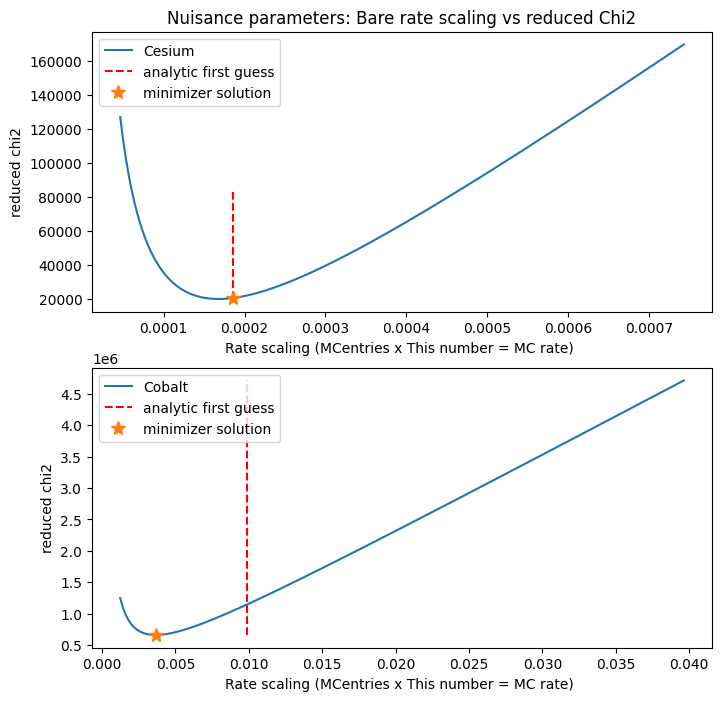

In [57]:
comp1.SetBinRanges(firstBin = 0) # set first bin as 1 and lastBin at 10 counts

# calculate the 1D space
scalingX_Cs = np.linspace(comp1.csGuess/4., comp1.csGuess * 4., 200)
chi2Full_Cs = np.array([comp1.getCsBarechi2(scale) for scale in scalingX_Cs])
comp1.minimizeRateScaling(option = "CsBare")

scalingX_Co = np.linspace(comp1.coGuess/8., comp1.coGuess * 4., 200)
chi2Full_Co = np.array([comp1.getCoBarechi2(scale) for scale in scalingX_Co])
comp1.minimizeRateScaling(option = "CoBare")

print("firstBin:", comp1.csBareMap[2].firstBin)

## plot it
fig, (ax, ax2) = plt.subplots(2, 1, figsize = (8, 8))

ax.plot(scalingX_Cs, chi2Full_Cs, label = "Cesium")
ax.vlines(comp1.csGuess, min(chi2Full_Cs), max(chi2Full_Cs)/2, color = "r", linestyle = "--", label = "analytic first guess")
ax.plot(comp1.csBareNuis, comp1.getCsBarechi2(comp1.csBareNuis), linewidth = 0, marker= "*", markersize = 10, label = "minimizer solution")

ax.set_title("Nuisance parameters: Bare rate scaling vs reduced Chi2")
ax.set_xlabel("Rate scaling (MCentries x This number = MC rate) ")
ax.set_ylabel("reduced chi2")
ax.legend()

ax2.plot(scalingX_Co, chi2Full_Co, label = "Cobalt")
ax2.vlines(comp1.coGuess, min(chi2Full_Co), max(chi2Full_Co), color = "r", linestyle = "--", label = "analytic first guess")
ax2.plot(comp1.coBareNuis, comp1.getCoBarechi2(comp1.coBareNuis), linewidth = 0, marker= "*", markersize = 10, label = "minimizer solution")

ax2.set_xlabel("Rate scaling (MCentries x This number = MC rate) ")
ax2.set_ylabel("reduced chi2")
ax2.legend()

plt.show()

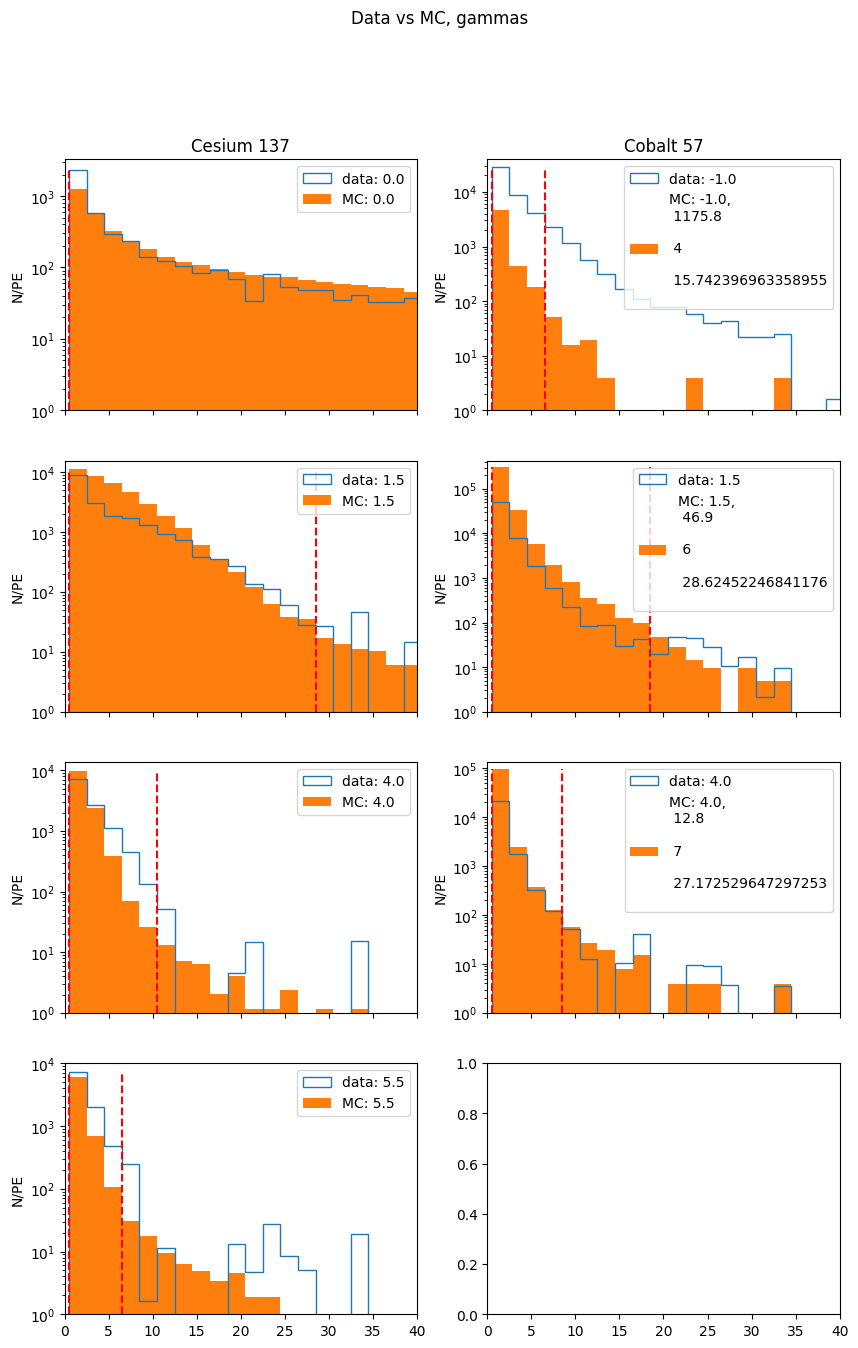

In [58]:
fig, axs = plt.subplots(4, 2, figsize = (10, 15), sharex=True)

# comp1.SetBinRanges(firstBin = FIRSTBIN) # set first bin as 1 and lastBin at 10 counts
# comp1.csBareMap[0].GetMaxBin(mcScale)
# print(comp1.getFullReducedChi2())

comp1.SetBinRanges(firstBin = 0) # set first bin as 1 and lastBin at 10 counts

## cesium
axs[0, 0].set_title("Cesium 137")
for i, ax in enumerate(axs[:, 0].flat[0:len(comp1.csBareMap)]):
  pair = comp1.csBareMap[i]
  rc = pair.rc
  mc = pair.mc
  ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype="step", label = "data: " + str(comp1.hScale - rc.mHeight))
  ax.hist(x = mc.mBinX, bins = mc.mBin_Edges, weights = mc.mRaw_Counts * comp1.csBareNuis * rc.GetRunTime(), label = "MC: " + str(mc.mRunPars.gammaHeight))

  maxVal = pair.GetMaxBin(comp1.csBareNuis)
  ax.vlines([rc.mBinX[pair.firstBin], rc.mBinX[pair.lastBin]], ymin =1, ymax = maxVal, color = "red", linestyle = "--")
  ax.set_yscale("log")
  ax.set_ylim(1, maxVal*1.4)
  ax.set_xlim(0, 40)
  ax.set_ylabel("N/PE")
  ax.legend()

axs[0, 1].set_title("Cobalt 57")
for i, ax in enumerate(axs[:, 1].flat[0:len(comp1.coBareMap)]):
  pair = comp1.coBareMap[i]
  rc = pair.rc
  mc = pair.mc

  s = f"""\n {rc.mBin_rawCounts[pair.lastBin+1]:0.1f}
  \n {mc.mRaw_Counts[pair.lastBin+1]}
  \n {mc.mRaw_Counts[pair.lastBin+1] * comp1.coBareNuis * rc.GetRunTime()}
  """
  ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype="step", label = "data: " + str(comp1.hScale - rc.mHeight))
  ax.hist(x = mc.mBinX, bins = mc.mBin_Edges, weights = mc.mRaw_Counts * comp1.coBareNuis * rc.GetRunTime(), label = f"MC: {str(mc.mRunPars.gammaHeight)}, {s}")

  maxVal = pair.GetMaxBin(comp1.coBareNuis)
  ax.vlines([rc.mBinX[pair.firstBin], rc.mBinX[pair.lastBin]], ymin =1, ymax = maxVal, color = "red", linestyle = "--")
  ax.set_yscale("log")
  ax.set_ylim(1, maxVal*1.4)
  ax.set_ylabel("N/PE")
  ax.legend()

fig.suptitle("Data vs MC, gammas")
plt.show()

In [59]:
## doing the real fucking thing ##
# comp2 = Comparator(realData)  # set it with real data
GLOBALVERBOSE = 0

## loading in mc data forloop
# print(pBatch1)
all_items = os.listdir(pBatch1)
folders = [item for item in all_items if os.path.isdir(os.path.join(pBatch1, item))]
folders = sorted(folders, key=lambda x: int(x))
print("folders:", folders)
# break

firstBin_array = [0, 1, 2]
xLYs = [[] for _ in range(len(firstBin_array))]
yChi2s = [[] for _ in range(len(firstBin_array))]
yCoXs = [[] for _ in range(len(firstBin_array))]
yCsXs = [[] for _ in range(len(firstBin_array))]
zScalingCs = [[] for _ in range(len(firstBin_array))]
zScalingCo = [[] for _ in range(len(firstBin_array))]


for folder in folders: # this is looping on phys pars

  #open dataset
  mcData = MCdataSet(pBatch1 + folder + "/", verbose = 0) # open dataset

  # setup for physics comparisons
  mcData.doCAcorrection_BinomialMC(NCA)
  mcData.setup_forComparison(NBINS, BINLOW, BINHIGH)

  mcData.popHeights(coBare = [-1.0, -0.5, 0.0]) # changing
  mcWanted = next((mc for mc in mcData.mCoBareList if mc.mRunPars.gammaHeight == -0.5), None) # change the height
  if mcWanted != None:
    print("found")
    mcWanted.mRunPars.gammaHeight = -1.0

  # do first sanity checks
  mcData.check_physPars_andDetPars(verbose = 0)

  comp1.mMCDataSet = mcData # point comp1 to mc data
  # print(comp1.mMCDataSet.mCsBareList)
  # print(comp1.mRealData.mCsBare)
  comp1.do_mapping() # put mc and rc objects together (correctly)
  # comp1.csBareMap = [pair for pair in comp1.csBareMap if pair.height != 0.0]

  # continue
  # remove things from MC here. MClist controls what gets compared to
  # comp1.csBareMap = [pair for pair in comp1.csBareMap if pair.height != 0.0] # remove 0.0 one

  for iFirstBin in firstBin_array:
    comp1.SetBinRanges(firstBin = iFirstBin) # set first bin as 1 and lastBin at 10 counts. could do directly on MC object...

    if comp1.checkNDOF() == False: # if any NDOF are zero get false
      continue
    # comp1.GuessOverallScaling() # set first guesses
    
    # do minimizations of independent data sets
    status1, res1 = comp1.minimizeRateScaling(option = "CsBare")
    status2, res2 = comp1.minimizeRateScaling(option = "CoBare")
    comp1.getFullReducedChi2()
    
    ly = comp1.mMCDataSet.mCsBareList[0].mPhysPars.ly
    totalChi2 = comp1.totalRedChi2
    nuis = comp1.csBareNuis

    if GLOBALVERBOSE:
      print("chi2 = ", comp1.getFullReducedChi2())      
      print("VERBOSE - folder:", folder, f"LY: {ly}, chi2 = {totalChi2}, nuis = {nuis}, iBin = {iFirstBin} \n")

    # print(status1, status2)
    if status1 == 0 or status2 == 0:
      print("ERROR - folder:", folder, f"LY: {ly}, chi2 = {totalChi2}, nuis = {nuis}, iBin = {iFirstBin} \n")
      print("chi2 = ", comp1.getFullReducedChi2())  
      print(res1, res2)
    else:
      xLYs[iFirstBin].append(ly)
      yChi2s[iFirstBin].append(comp1.totalRedChi2)
      yCsXs[iFirstBin].append(comp1.csBareRedChi2)
      # print(comp1.csBareRedChi2)
      yCoXs[iFirstBin].append(comp1.coBareRedChi2)
      zScalingCs[iFirstBin].append(comp1.csBareNuis)
      zScalingCo[iFirstBin].append(comp1.coBareNuis)

print("done building LY arrays")

folders: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17']


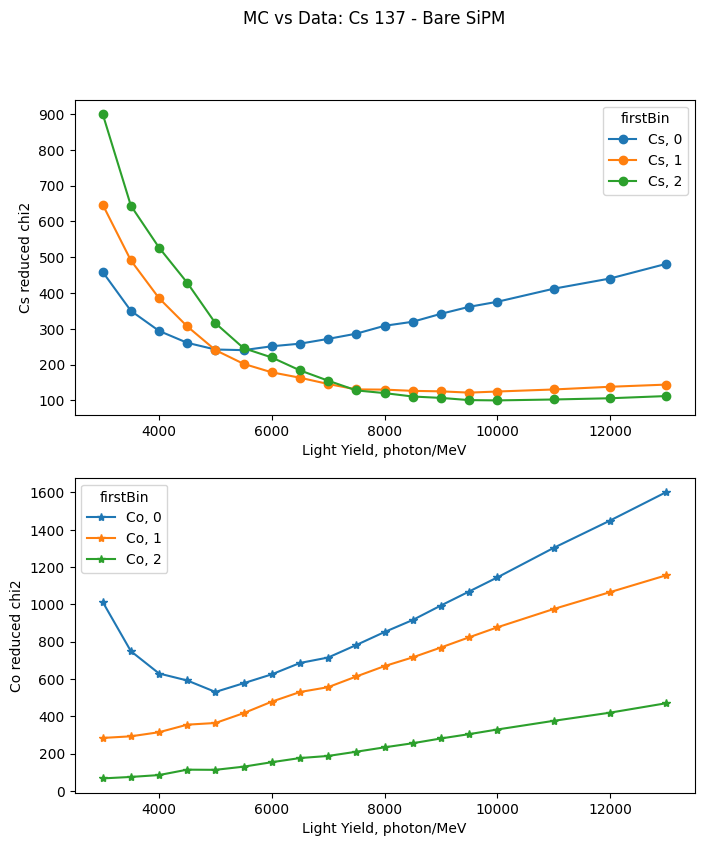

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (8, 9))
for iBin in firstBin_array:
  ax1.plot(xLYs[iBin], yCsXs[iBin], linestyle = "-", marker = "o", label = f"Cs, {iBin}")
  # ax2.plot(xLYs[iBin], zScaling[iBin], linestyle = "-", marker = "*", label = f"{iBin}")

ax1.set_xlabel("Light Yield, photon/MeV")
ax1.set_ylabel("Cs reduced chi2")
ax1.legend(title="firstBin")

for iBin in firstBin_array:
  ax2.plot(xLYs[iBin], yCoXs[iBin], linestyle = "-", marker = "*", label = f"Co, {iBin}")

ax2.set_xlabel("Light Yield, photon/MeV")
ax2.set_ylabel("Co reduced chi2")
ax2.legend(title="firstBin")

# ax1.set_ylim(450, 600)

# ax2.set_xlabel("Light Yield, photon/MeV")
# ax2.set_ylabel("Nuisance paramter (rate scaling)")
# ax2.legend(title="firstBin")

fig.suptitle("MC vs Data: Cs 137 - Bare SiPM")

plt.show()